# PRINT footprints and TF binding scores

[PRINT](https://www.nature.com/articles/s41586-024-08443-4) (Hu *et al.*,
*Nature* 2025) asks, at every base and every scale, whether Tn5 cut a
window **less than its sequence bias predicts** relative to the flanks —
the mark of something bound there. Small scales pick out transcription
factors, large ones nucleosomes. [scPrinter](https://github.com/buenrostrolab/scPrinter)
brought it to single-cell data and added a model that turns the footprint
around a site into a binding probability.

Epione runs the same computation in three calls:

```python
bias = epi.tl.tn5_bias(genome)                                   # PRINT CNN, on demand
fp   = epi.tl.multi_scale_footprint_region(adata, sites, groupby=..., bias=bias)
tfbs = epi.tl.tf_binding_score(adata, peaks, groupby=..., bias=bias)
```

**What is scPrinter's, and what is not.** The numbers are scPrinter's —
window geometry, learned null ("dispersion model"), smoothing, binding
model and published weights — and they match it **bit for bit** (last
section). The machinery is not: scPrinter keeps state in a `printer`
object over a backed AnnData plus a `_supp/` directory, passes models to
workers through `globals()`, and needs snapATAC2's genome-wide insertion
matrix and a precomputed bias file of **10.9 GB** for mm10. Here the
inputs are an insertion track read from the fragments file on demand, a
bias track computed on demand by a 0.1 MB CNN, and models loaded once.

| step | scPrinter | Epione |
|---|---|---|
| insertions | genome-wide `cells × bp` matrix (snapATAC2) | tabix read of the window asked for |
| Tn5 bias | 10.9 GB file, loaded whole per call | 0.1 MB CNN on the bases asked for |
| null | dispersion MLP (torch) | same MLP, same ops |
| results | h5ad side-cars keyed by region strings | dataclasses |

The sample is the one used in the scooby tutorial: GSE308623 `P2S1`,
mouse brain at P2, spatial ATAC, mm10, chr19.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import anndata as ad
import pysam
import warnings
warnings.filterwarnings('ignore', module='tqdm')


def _find_repo(start):  # works from the source tree or a pip install
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi

DATA  = pathlib.Path(os.environ.get('SCOOBY_TUTORIAL_DATA', (CODE or pathlib.Path.cwd()).parent))
FRAG  = DATA / 'scooby_bench' / 'P2S1.fragments.tsv.gz'
POS   = DATA / 'scooby_bench' / 'P2S1.positions.csv'
FASTA = DATA / 'genome' / 'mm10' / 'chr19.fa'
CHROM = 'chr19'
for p in (FRAG, POS, FASTA):
    if not p.exists():
        raise FileNotFoundError(f'{p} — see "Getting the inputs" in t_scooby_bridge')

epi.pl.plot_set()
BP = FuncFormatter(lambda v, _: f'{v:,.0f}')       # 61,266,400 rather than 61266400
# Four hues from epi.pl.sc_color, colour-blind safe, in a fixed order: bands 1-4,
# and first / second series wherever two are compared.
GROUP = ['#279AD7', '#EF7B77', '#5E4D9A', '#368650']
assert all(c in epi.pl.sc_color for c in GROUP)


def restyle(fig, tracks=(), fontsize=12):
    # epi.pl's two PRINT plots draw in a light theme of their own (grey
    # ticks, open frames, their own group colours). This puts them back in
    # the plot_set() look: black frames and text, groups in GROUP order.
    for ax in fig.axes:
        if ax.get_label() != '<colorbar>':
            for sp in ax.spines.values():
                sp.set_visible(True); sp.set_color('k')
            ax.grid(False)
        ax.tick_params(colors='k', labelsize=fontsize - 1)
        for lab in (ax.xaxis.label, ax.yaxis.label):
            lab.set_color('k'); lab.set_fontsize(fontsize)
        for t in ax.texts:
            t.set(color='k', fontsize=fontsize - 1, fontweight='normal')
    for k, ax in enumerate(tracks):
        ax.collections[0].set_facecolor(GROUP[k])            # the filled cut track
    if fig._suptitle is not None:
        fig._suptitle.set(color='k', fontweight='normal', fontsize=fontsize + 2)

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Cells, groups and peaks

Each 50 µm spot is one barcode. Groups here are four dorsal→ventral bands
of the section — crude, but deep: ~1,800 spots each, which is what
footprinting needs (a footprint is a *shortage* of cuts, so it takes many
cuts to see one).

In [2]:
pos = (pd.read_csv(POS, header=None, names=['bc', 'in_tissue', 'row', 'col', 'pr', 'pc'])
         .query('in_tissue == 1').reset_index(drop=True))
edges = np.quantile(pos['row'], [0, .25, .5, .75, 1])
band = np.clip(np.digitize(pos['row'], edges[1:-1]), 0, 3)

adata = ad.AnnData(
    X=np.zeros((len(pos), 1), dtype=np.float32),
    obs=pd.DataFrame({'band': [f'band {b + 1}' for b in band]}, index=pos['bc'] + '-1'),
)
adata.uns['files'] = {'fragments': str(FRAG)}
adata.uns['reference_sequences'] = {CHROM: pysam.FastaFile(str(FASTA)).get_reference_length(CHROM)}
adata.obs['band'].value_counts().sort_index()

band
band 1    1750
band 2    1762
band 3    1795
band 4    1824
Name: count, dtype: int64

In [3]:
%%time
# Stand-in peaks: the 200 densest 500-bp bins on chr19, widened to 1 kb.
keep, cnt = set(adata.obs_names), {}
for line in pysam.TabixFile(str(FRAG)).fetch(CHROM):
    f = line.split('\t', 4)
    if f[3] in keep:
        for p in (int(f[1]), int(f[2])):
            cnt[p // 500] = cnt.get(p // 500, 0) + 1
top = sorted(cnt.items(), key=lambda kv: -kv[1])[:200]
peaks = pd.DataFrame({'chrom': CHROM,
                      'start': [b * 500 - 250 for b, _ in top],
                      'end':   [b * 500 + 750 for b, _ in top],
                      'cuts':  [n for _, n in top]})
peaks.head()

CPU times: user 3.61 s, sys: 15.8 ms, total: 3.62 s
Wall time: 3.62 s


,chrom,start,end,cuts
0,chr19,61266250,61267250,2520
1,chr19,8251750,8252750,2096
2,chr19,59345250,59346250,1621
3,chr19,6979750,6980750,1353
4,chr19,61266750,61267750,1290


## Part 3 · Tn5 bias

`epi.tl.tn5_bias` returns an object with one method,
`track(chrom, start, end)`. The default is PRINT's CNN, run only on the
bases asked for. It reproduces scPrinter's genome-wide inference bit for
bit: CPU convolutions round differently for different input lengths, so
the region is run through the very chunks scPrinter's chromosome-wide
pass would have used.

The older hexamer table is still available. The two models were fitted
to **different cut conventions** — PRINT to cuts at a fragment's `start`
and `end`, the hexamer table to `start` and `end − 1` — and each bias
object carries its own, so footprinting reads insertions the way the
bias expects. A one-base mismatch here blurs every footprint.

In [4]:
%%time
bias = epi.tl.tn5_bias(FASTA)                     # PRINT CNN (downloads 0.1 MB once)
bias.track(CHROM, 1_000_000, 1_001_000)           # first call loads the model
t0 = time.time()
b = bias.track(CHROM, int(peaks.start[1]), int(peaks.end[1]))
print(f'1 kb of PRINT bias in {1e3 * (time.time() - t0):.0f} ms (model loaded);',
      f'cut convention {bias.shift}')

table = epi.tl.compute_tn5_bias_table(str(FRAG), str(FASTA), chroms=[CHROM])
kmer = epi.tl.tn5_bias(FASTA, method='kmer', table=table)
print(f'hexamer table: {table.size:,} 6-mers; cut convention {kmer.shift}')

1 kb of PRINT bias in 12 ms (model loaded); cut convention (0, 0)


  └─ Tn5 bias: scanned 3,030,303 fragments, 6,060,577 cuts; k=6, bias range [0.013, 10.965]
hexamer table: 4,096 6-mers; cut convention (0, -1)
CPU times: user 25.2 s, sys: 1.37 s, total: 26.6 s
Wall time: 26.7 s


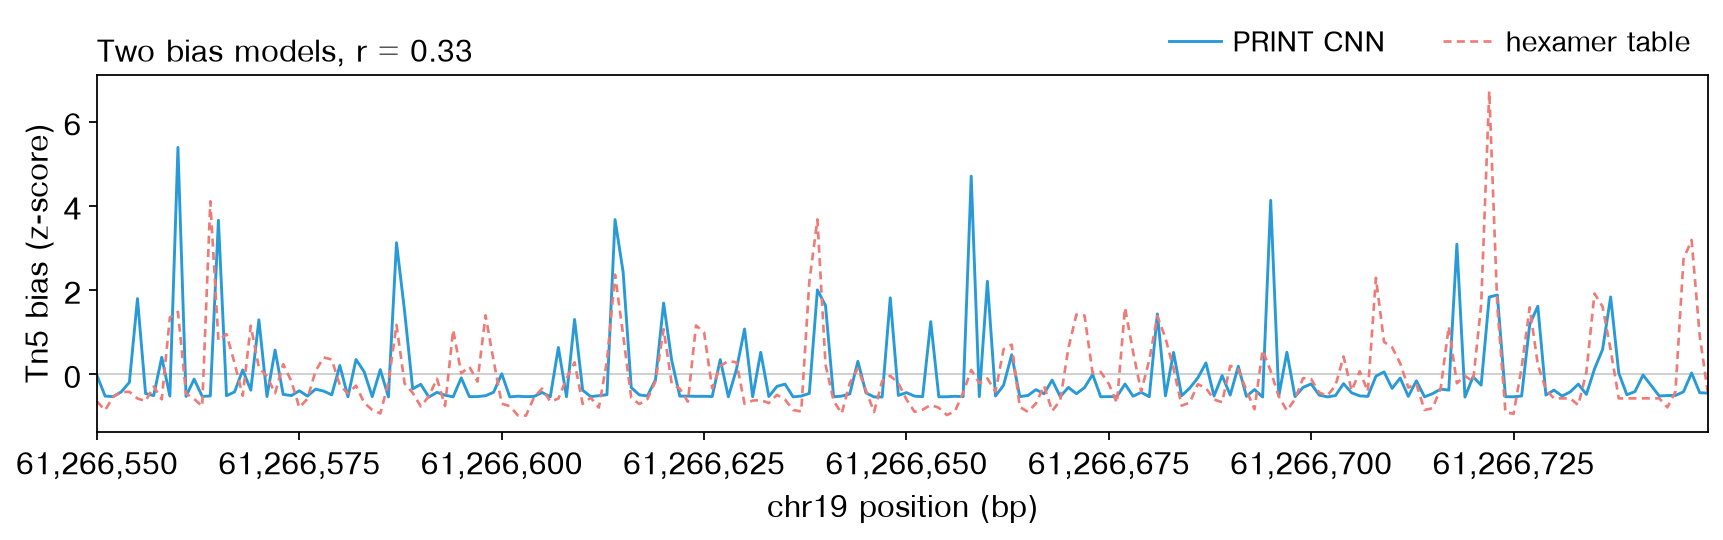

In [5]:
s0 = int(peaks.start[0]) + 300
x = np.arange(s0, s0 + 200)
pb, kb = bias.track(CHROM, s0, s0 + 200), kmer.track(CHROM, s0, s0 + 200)
z = lambda v: (v - v.mean()) / v.std()
r = np.corrcoef(pb, kb)[0, 1]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(x, z(pb), color=GROUP[0], lw=1.3, label='PRINT CNN')
ax.plot(x, z(kb), color=GROUP[1], lw=1.2, ls=(0, (3, 2)), label='hexamer table')
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2, borderaxespad=0.2,
          frameon=False, handlelength=1.8)
ax.axhline(0, color='0.8', lw=0.8, zorder=0)
ax.grid(False)
ax.set_ylabel('Tn5 bias (z-score)')
ax.set_xlabel(f'{CHROM} position (bp)')
ax.xaxis.set_major_formatter(BP)
ax.set_xlim(x[0], x[-1])
ax.set_title(f'Two bias models, r = {r:.2f}', loc='left')
plt.tight_layout(); plt.show()

The two models correlate only weakly at base resolution. They are not
interchangeable: the CNN reads a 101-bp context and was trained on
deproteinised DNA, the hexamer table sees 6 bp and was estimated from
this sample's own (protein-bound) chromatin. The CNN is also the bias the
dispersion null and the binding model were fitted to, so pairing those
with the hexamer table would give uncalibrated scores — Epione refuses
that combination.

## Part 4 · Multi-scale footprint of one peak

`multi_scale_footprint_region` is the function Epione already had; it
now takes a `bias=` and picks PRINT's learned null automatically when
the bias is PRINT's. Above each heatmap is the evidence it rests on: cuts
observed in that band (filled) and the cuts the bias predicts (dashed,
rescaled to the same total). Footprints are where the filled track drops
below the dashed one.

In [6]:
%%time
dispersion = epi.tl.DispersionModel.load()        # 0.7 MB, once
summit = int(peaks.start[0]) + 500
fp = epi.tl.multi_scale_footprint_region(
    adata, [{'chrom': CHROM, 'center': summit}], groupby='band',
    bias=bias, dispersion=dispersion, flank=600)
print(fp.score.shape, '(groups, scales, positions);',
      'cuts per band:', dict(zip(fp.groups, fp.insertions.sum(1).astype(int))))

└─ multi_scale_footprint_region: 1 site(s) × 4 groups · print bias · dispersion null
(4, 50, 1201) (groups, scales, positions); cuts per band: {'band 1': np.int64(1036), 'band 2': np.int64(1049), 'band 3': np.int64(996), 'band 4': np.int64(1152)}
CPU times: user 1.35 s, sys: 6.07 ms, total: 1.36 s
Wall time: 193 ms


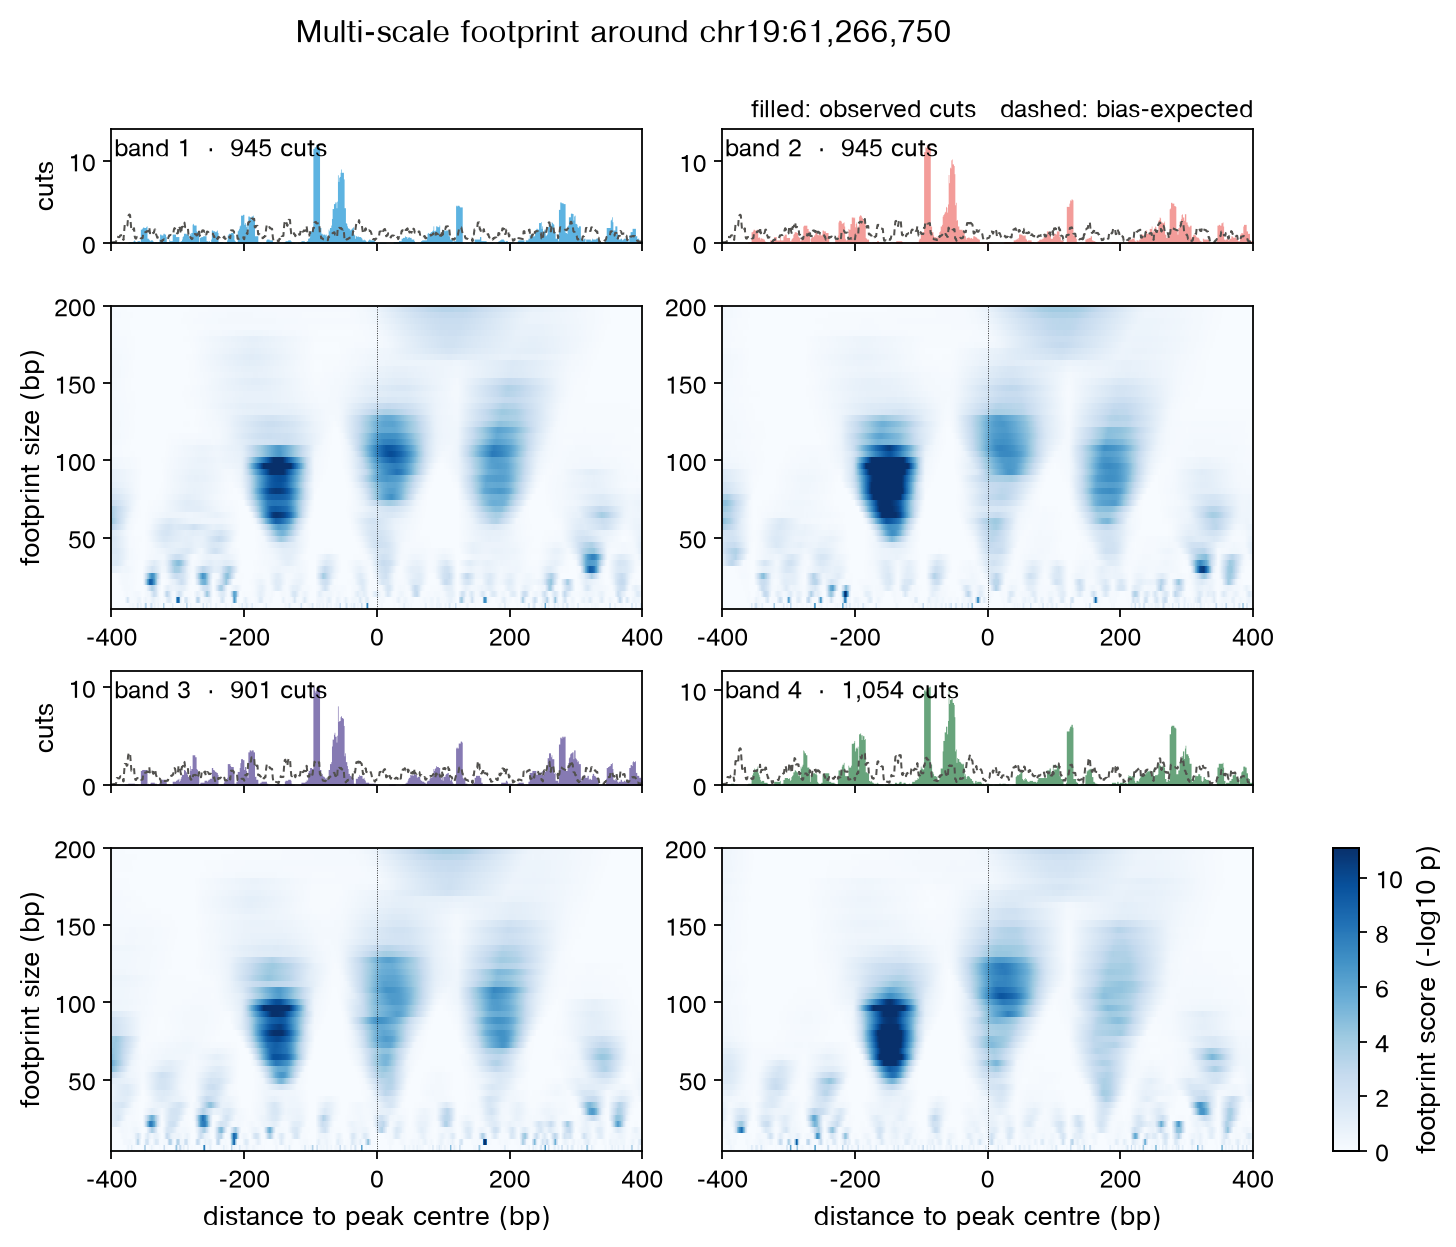

In [7]:
# Scores near the window edge have truncated flanks: read ±600, show ±400.
fig, axes = epi.pl.plot_multi_scale_footprint_region(
    fp, ncols=2, zoom=400, vpercentile=99.5, show=False, figsize=(10, 8.4),
    title=f'Multi-scale footprint around {CHROM}:{summit:,}')
restyle(fig, tracks=fig.track_axes)
axes[0].get_gridspec().update(wspace=0.22, hspace=0.3)
for ax in axes:
    if ax.get_xlabel():
        ax.set_xlabel('distance to peak centre (bp)')
for ax in fig.track_axes[::2]:
    ax.set_ylabel('cuts', fontsize=12)
fig.track_axes[1].text(1, 1.06, 'filled: observed cuts   dashed: bias-expected',
                       transform=fig.track_axes[1].transAxes, ha='right', va='bottom', fontsize=11)
fig.axes[-1].set_ylabel('footprint score (−log10 p)', fontsize=12)   # the colorbar
plt.show()

## Part 5 · Why the learned null matters

PRINT's dispersion model is the piece that separates it from a textbook
test. A binomial null assumes each cut is an independent draw; real Tn5
data are overdispersed, so a binomial test calls far more "footprints"
than are there. Same insertions, same bias, two nulls:

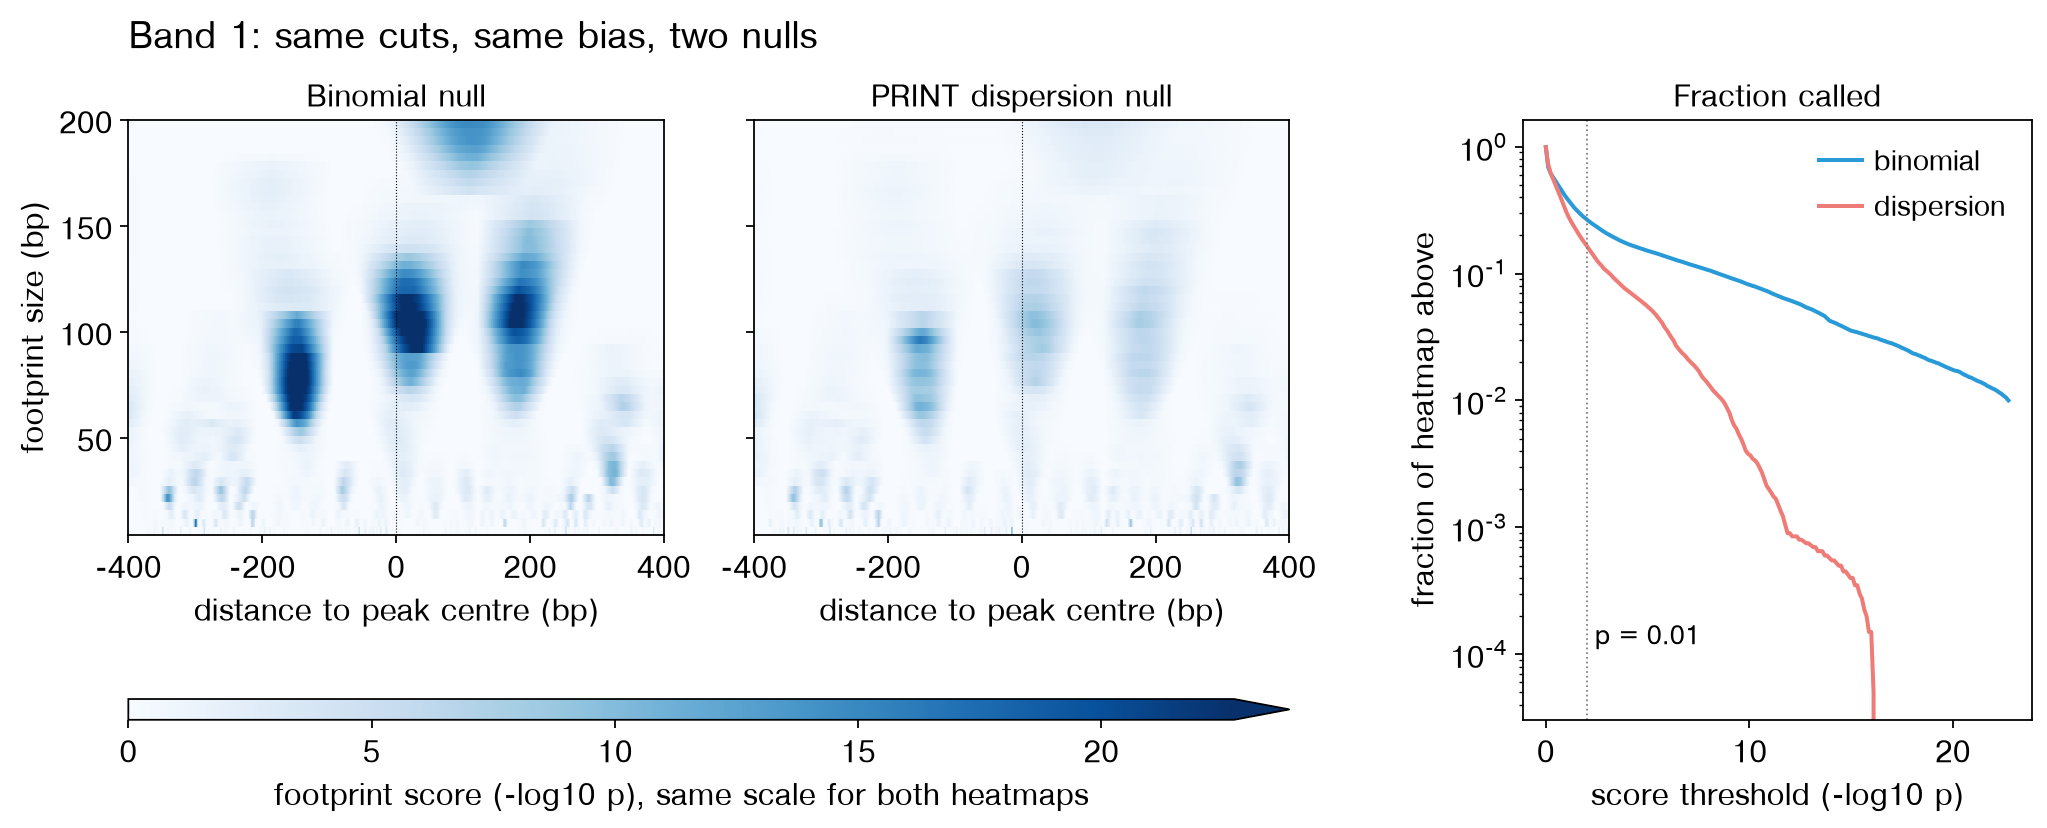

fraction with p < 0.01 — binomial: 0.268   dispersion: 0.167


In [8]:
fp_bin = epi.tl.multi_scale_footprint_region(
    adata, [{'chrom': CHROM, 'center': summit}], groupby='band',
    bias=bias, null='binomial', flank=600, verbose=False)

g = 0
inner = np.abs(fp.positions) <= 400           # drop the edge-truncated flanks
S_disp, S_bin = fp.score[g][:, inner], fp_bin.score[g][:, inner]
vmax = np.nanpercentile(np.stack([S_disp, S_bin]), 99.5)    # one colour scale for both

fig = plt.figure(figsize=(13, 5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.05], width_ratios=[1, 1, 0.1, 0.95],
                      hspace=0.75, wspace=0.22, left=0.07, right=0.985, top=0.85, bottom=0.1)
h0 = fig.add_subplot(gs[0, 0]); h1 = fig.add_subplot(gs[0, 1], sharey=h0)
lax = fig.add_subplot(gs[:, 3])
for ax, S, name in ((h0, S_bin, 'Binomial null'), (h1, S_disp, 'PRINT dispersion null')):
    im = ax.imshow(S, aspect='auto', origin='lower', cmap='Blues',
                   vmin=0, vmax=vmax, interpolation='nearest',
                   extent=[-400, 400, 2 * fp.scales[0], 2 * fp.scales[-1]])
    ax.axvline(0, color='k', lw=0.5, ls=':')
    ax.grid(False)
    ax.set_title(name)
    ax.set_xlabel('distance to peak centre (bp)')
h0.set_ylabel('footprint size (bp)')
h1.tick_params(labelleft=False)
cb = fig.colorbar(im, cax=fig.add_subplot(gs[1, :2]), orientation='horizontal', extend='max')
cb.set_label('footprint score (−log10 p), same scale for both heatmaps')

thr = np.linspace(0, vmax, 200)
for S, col, name in ((S_bin, GROUP[0], 'binomial'), (S_disp, GROUP[1], 'dispersion')):
    lax.plot(thr, [(S > t).mean() for t in thr], color=col, lw=1.8, label=name)
lax.axvline(2, color='0.5', lw=0.8, ls=':')
lax.text(2.4, 1.2e-4, 'p = 0.01', fontsize=12)
lax.set_yscale('log'); lax.set_xlabel('score threshold (−log10 p)')
lax.set_ylabel('fraction of heatmap above')
lax.legend(loc='upper right', frameon=False, handlelength=1.5)
lax.grid(False)
lax.set_title('Fraction called')
fig.suptitle(f'{fp.groups[g].capitalize()}: same cuts, same bias, two nulls', x=0.07, ha='left')
plt.show()
print('fraction with p < 0.01 — binomial: {:.3f}   dispersion: {:.3f}'.format(
      (S_bin > 2).mean(), (S_disp > 2).mean()))

## Part 6 · TF binding scores

> **Not the default any more.** Epione's default per-site binding score is
> `epi.tl.tf_binding(adata, motif_sites)` (`method='occupancy'`, a thermodynamic
> motif-accessibility score; see [t_tf_binding](t_tf_binding.ipynb)). On ENCODE ChIP-seq
> ground truth in four cell lines it ranked bound motif sites better than PRINT
> (median AUROC 0.89-0.91 vs 0.72-0.77) and runs ~70x faster. PRINT's score below
> is unchanged and is also `epi.tl.tf_binding(..., method='print')`; it remains the
> tool for footprint-shape questions and motif-free scans.

`tf_binding_score` computes the footprint over each whole peak at the
six scales PRINT's binding model uses, then scores the 201-bp multi-scale
footprint around each site. Without motifs, every peak is tiled every
10 bp — a scan for any bound factor. Each score is a probability.

In [9]:
%%time
tfbs = epi.tl.tf_binding_score(adata, peaks, groupby='band', bias=bias, dispersion=dispersion)
tfbs.to_frame().head()

└─ tf_binding_score: 16,000 sites in 200 region(s) x 4 groups
CPU times: user 39.3 s, sys: 263 ms, total: 39.6 s
Wall time: 4.36 s


,chrom,center,strand,region,position,group,score
0,chr19,61266355,+,chr19:61266250-61267250,105,band 1,0.025844
1,chr19,61266355,+,chr19:61266250-61267250,105,band 2,0.010080
2,chr19,61266355,+,chr19:61266250-61267250,105,band 3,0.002697
3,chr19,61266355,+,chr19:61266250-61267250,105,band 4,0.005405
4,chr19,61266365,+,chr19:61266250-61267250,115,band 1,0.054385


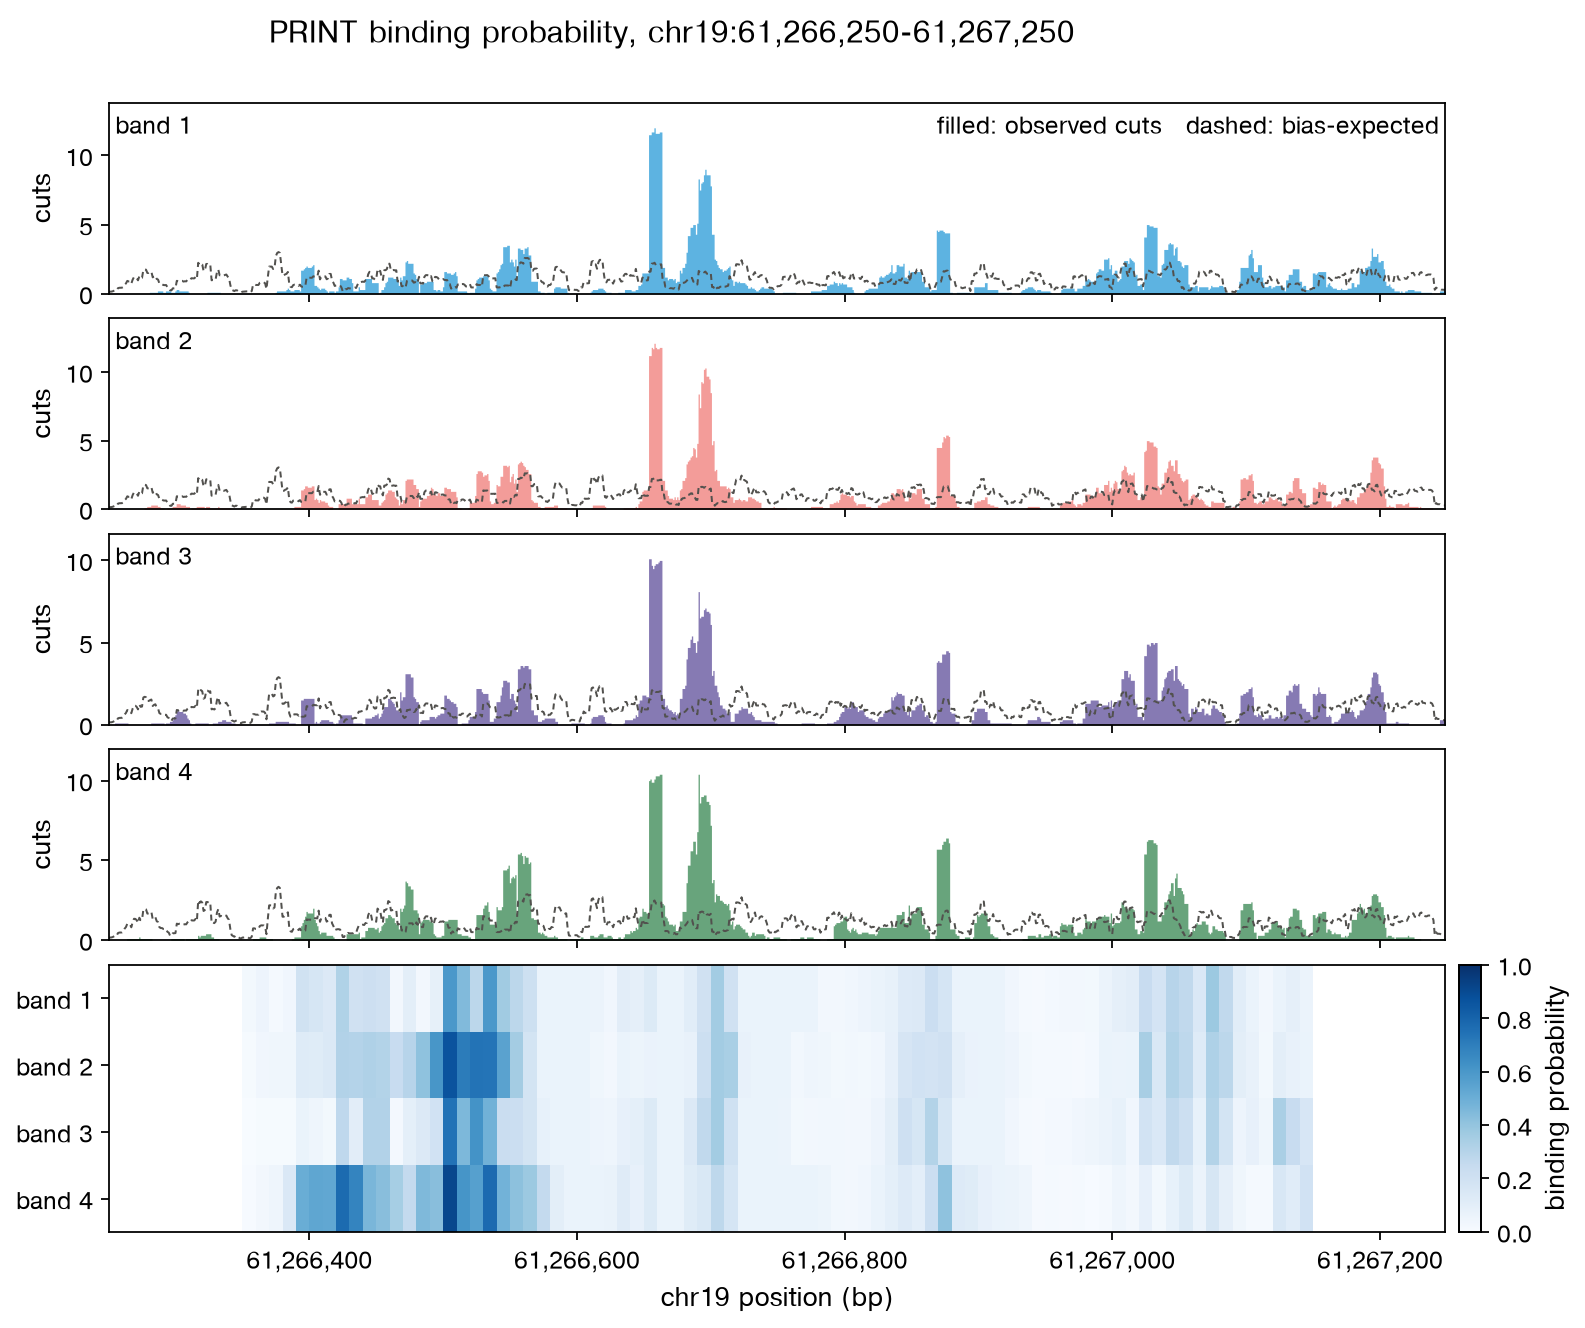

In [10]:
region = f'{CHROM}:{peaks.start[0]}-{peaks.end[0]}'
fig, axes = epi.pl.plot_tf_binding_score(
    tfbs, region=region, show=False, figsize=(11, 8.4),
    title=f'PRINT binding probability, {CHROM}:{peaks.start[0]:,}-{peaks.end[0]:,}')
restyle(fig, tracks=axes[:-1])
axes[-1].xaxis.set_major_formatter(BP)
fig.axes[-1].set_ylabel('binding probability', fontsize=12)     # the colorbar
for ax in axes[:-1]:
    ax.set_ylabel('cuts', fontsize=12)
plt.show()

Across all 200 peaks, how do two bands compare site by site? Read the
highlighted sites as **candidates**, not differential binding: at ~950
cuts per band per peak, a 0.3 difference in probability is well within
what sampling noise alone produces. Calling a site differentially bound
needs replicate sections or a permutation null over spots; the cut-track
view above is how to inspect any one of them.

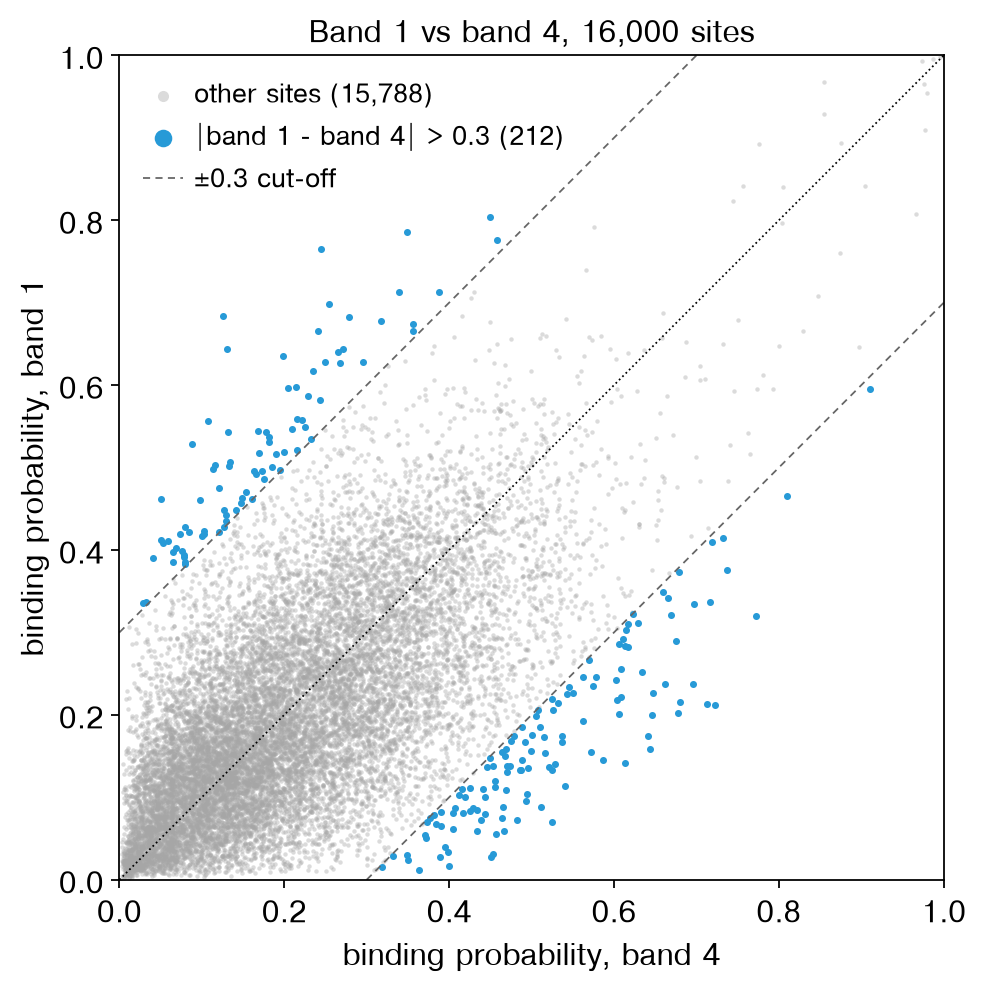

In [11]:
i1, i4 = tfbs.groups.index('band 1'), tfbs.groups.index('band 4')
d = tfbs.score[i1] - tfbs.score[i4]
hi = np.abs(d) > 0.3
fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.scatter(tfbs.score[i4][~hi], tfbs.score[i1][~hi], s=4, color='0.65', alpha=0.4, lw=0,
           rasterized=True, label=f'other sites ({(~hi).sum():,})')
ax.scatter(tfbs.score[i4][hi], tfbs.score[i1][hi], s=10, color=GROUP[0], lw=0,
           label=f'|band 1 − band 4| > 0.3 ({hi.sum()})')
ax.plot([0, 1], [0, 1], color='k', lw=0.8, ls=':')
for off in (0.3, -0.3):                                   # the |Δ| = 0.3 cut-off
    ax.plot([max(0, -off), min(1, 1 - off)], [max(0, off), min(1, 1 + off)],
            color='0.4', lw=0.8, ls=(0, (4, 3)), label='±0.3 cut-off' if off > 0 else None)
ax.set_xlabel('binding probability, band 4'); ax.set_ylabel('binding probability, band 1')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
ax.legend(loc='upper left', markerscale=2.5, handlelength=1.5, fontsize=12, frameon=False)
ax.grid(False)
ax.set_title(f'Band 1 vs band 4, {tfbs.score.shape[1]:,} sites')
plt.tight_layout(); plt.show()

## Part 7 · Exactness against scPrinter

The claim that these are scPrinter's numbers is checked, not assumed:
here scPrinter's own `multiscale_footprints` and
`getRegionBindingScore` — lifted verbatim from its source — are run on
the **same real insertion and bias tracks** as above and compared with
`np.array_equal`. The test suite (`tests/test_print.py`) additionally
checks the CNN bias against scPrinter's chromosome-wide inference and
every one of the 99 scales' p-values.

Set `SCPRINTER_SRC` to the `scprinter/` directory of a clone of
scPrinter to run this section.

In [12]:
SRC = os.environ.get('SCPRINTER_SRC')
if not SRC:
    print('SCPRINTER_SRC not set — skipping.')
else:
    import ast, importlib.util, torch
    parts = ['import os, warnings, time', 'import numpy as np, torch, h5py, scipy, scipy.stats',
             'import torch.nn.functional as F', 'from scipy.ndimage import maximum_filter']
    want = {'utils.py': {'rz_conv', 'load_entire_hdf5', 'loadDispModel', 'loadBindingScoreModel_pt',
                         'strided_lastaxis'},
            'footprint.py': {'predictDispersion_jit', 'footprintWindowSum', 'footprintScoring',
                             'regionFootprintScore', 'multiscale_footprints'},
            'TFBS.py': {'getRegionBindingScore'}}
    for fname, names in want.items():
        text = (pathlib.Path(SRC) / fname).read_text(); lines = text.splitlines(keepends=True)
        for node in ast.parse(text).body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                first = (node.decorator_list[0].lineno if node.decorator_list else node.lineno) - 1
                parts.append(''.join(lines[first:node.end_lineno]))
    ref_path = pathlib.Path(os.environ.get('TMPDIR', '/tmp')) / 'scprinter_ref_nb.py'
    ref_path.write_text('\n\n'.join(parts))
    spec = importlib.util.spec_from_file_location('scprinter_ref_nb', ref_path)
    ref = importlib.util.module_from_spec(spec); sys.modules['scprinter_ref_nb'] = ref
    spec.loader.exec_module(ref)

    ref_disp = ref.loadDispModel(dispersion.path)
    want_fp = ref.multiscale_footprints(fp.insertions.astype(float), fp.bias.astype(float),
                                        ref_disp, modes=fp.scales, smoothRadius=None)
    print('multi-scale footprint, real data:', fp.score.shape,
          '→ identical:', np.array_equal(fp.score, want_fp.astype(np.float32)))

    rid = f'{CHROM}:{peaks.start[0]}-{peaks.end[0]}'
    tr = tfbs.tracks[rid]
    net = ref.loadBindingScoreModel_pt(epi.tl.fetch_print_model('tf_binding'))
    # scPrinter's own tiling sets Score = 1 on every tile.
    tiles = epi.tl._print._tile_sites(tr['start'], tr['end'], 10).assign(Score=1)

    class _Region:
        df = pd.DataFrame({'Start': [tr['start']], 'End': [tr['end']]})

    with torch.no_grad():
        want_tf = ref.getRegionBindingScore('r', tr['insertions'], tr['bias'], _Region(),
                                            [ref_disp[str(s)] for s in net['scales']], net,
                                            sites=tiles)
    got_tf = tfbs.score[:, (tfbs.sites['region'] == rid).to_numpy()]
    print('TF binding scores, real data:', got_tf.shape,
          '→ identical:', np.array_equal(got_tf, want_tf['BindingScore']))

multi-scale footprint, real data: (4, 50, 1201) → identical: True
TF binding scores, real data: (4, 80) → identical: True


## Summary

| | |
|---|---|
| Inputs | fragments file + FASTA; no snapATAC2, no genome-wide bias file |
| Tn5 bias | `epi.tl.tn5_bias(genome)` — PRINT CNN on demand, bit-identical to scPrinter |
| Footprints | `epi.tl.multi_scale_footprint_region(..., bias=bias)` — learned null by default with PRINT bias |
| Binding | `epi.tl.tf_binding_score(...)` → `TFBindingResult` (`.score`, `.sites`, `.to_frame()`); the default per-site score is `epi.tl.tf_binding` ([t_tf_binding](t_tf_binding.ipynb)) |
| Plots | `epi.pl.plot_multi_scale_footprint_region`, `epi.pl.plot_tf_binding_score` — evidence above score |
| Exactness | `np.array_equal` against scPrinter's own functions on real data |

Not included yet: **seq2PRINT**, scPrinter's sequence model that learns to
predict these footprints from DNA. It is a training workflow (GPU, five
folds, LoRA per cell state) rather than an analysis step, and will come
as `epione.models.seq2print`, next to the scooby bridge.